C3S CORDEX - Remapping with clisops + xESMF - Brief Comparison with ATLAS
=========================================================================

This brief comparison of the C3S ATLAS with clisops remapping with regards to CORDEX datasets complements the detailed comparison of both remapping approaches shown in deliverable `C3S2 380_D380 2.1.10` (Update WPS operations with regridding for CMIP5 & CMIP6). While the comparison in deliverable `2.1.10` discusses the differences in the source code of both implementations of the xESMF-powered remapping in detail, here, the results of both approaches applied on CORDEX data are shown side by side for arbitrarily selected CORDEX datasets.

## Basic Imports

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import xesmf as xe
import xarray as xr
import cf_xarray as cfxr
import clisops.core as clore
import clisops.ops as clops
import clisops as cl
import roocs_grids as rg
from glob import glob

## Allow multiple outputs per cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

## Turn off warnings?
import warnings
warnings.simplefilter("ignore")

# Flush weights cache
clore.weights_cache_flush(verbose=True)

print("Using xESMF in version %s" % xe.__version__)
print("Using xarray in version %s" % xr.__version__)
print("Using cf_xarray in version %s" % cfxr.__version__)
print("Using clisops in version %s" % cl.__version__)

Flushing the clisops weights cache ('/home/ms/.local/share/clisops/grid_weights'). Removing ...
No weight or grid files found. Cache empty?
Initialized new weights cache at /home/ms/.local/share/clisops/grid_weights
Using xESMF in version 0.8.11.dev8+g2258382.d20250815
Using xarray in version 2025.7.0
Using cf_xarray in version 0.10.8
Using clisops in version 0.16.2


## Comparison with ATLAS_v0

The ATLAS features datasets at 0.5 degree resolution, while the target grids for clisops the `adaptive` target grid is chosen, thus following the average resolution of the CORDEX data.

In [2]:
import math
import textwrap


def plot_ds(ds_atlas, ds, subtitle0=None, subtitle1=None, cbar=False):
    # Create panel plot
    fig, axes = plt.subplots(
        ncols=2,
        nrows=1,
        figsize=(20, 7),
        subplot_kw={"projection": ccrs.Mercator(central_longitude=150)},
    )

    ds_atlas.plot.pcolormesh(
        ax=axes[0],
        vmin=250,
        vmax=320,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    ds.plot.pcolormesh(
        ax=axes[1],
        vmin=250,
        vmax=320,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    if subtitle0:
        axes[0].title.set_text("\n".join(textwrap.wrap(subtitle0, 40)))
    if subtitle1:
        axes[1].title.set_text("\n".join(textwrap.wrap(subtitle1, 40)))

    for axis in axes.flatten():
        axis.coastlines()
        axis.set_xlabel("lon")
        axis.set_ylabel("lat")
    plt.show()

In [3]:
ds_atlas = {}
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    ds_atlas[domain] = xr.open_dataset(
        f"testdata/ATLAS_v0_CORDEX/t_CORDEX-{domain}_historical_mon_197001-200512.nc"
    )

In [4]:
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    for i in range(ds_atlas[domain].sizes["member"]):
        print()
        print(i)
        # id example: c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915
        id = f"c3s-cordex.output.{domain}-*.{ds_atlas[domain].rcm_institution.data[i]}.{ds_atlas[domain].gcm_institution.data[i]}-{ds_atlas[domain].gcm_model.data[i]}.historical.{ds_atlas[domain].gcm_variant.data[i]}.{ds_atlas[domain].rcm_institution.data[i]}-{ds_atlas[domain].rcm_model.data[i]}.{ds_atlas[domain].rcm_variant.data[i]}.tas.mon"
        print(id)
        print(id.replace(".", "/") + "/*/*_1970-*.nc")


0
c3s-cordex.output.AFR-*.CCCma.CCCma-CanESM2.historical.r1i1p1.CCCma-CanRCM4.r2.tas.mon
c3s-cordex/output/AFR-*/CCCma/CCCma-CanESM2/historical/r1i1p1/CCCma-CanRCM4/r2/tas/mon/*/*_1970-*.nc

1
c3s-cordex.output.AFR-*.SMHI.CCCma-CanESM2.historical.r1i1p1.SMHI-RCA4.v1.tas.mon
c3s-cordex/output/AFR-*/SMHI/CCCma-CanESM2/historical/r1i1p1/SMHI-RCA4/v1/tas/mon/*/*_1970-*.nc

2
c3s-cordex.output.AFR-*.UQAM.CCCma-CanESM2.historical.r1i1p1.UQAM-CRCM5.v1.tas.mon
c3s-cordex/output/AFR-*/UQAM/CCCma-CanESM2/historical/r1i1p1/UQAM-CRCM5/v1/tas/mon/*/*_1970-*.nc

3
c3s-cordex.output.AFR-*.CLMcom.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/AFR-*/CLMcom/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

4
c3s-cordex.output.AFR-*.SMHI.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.SMHI-RCA4.v1.tas.mon
c3s-cordex/output/AFR-*/SMHI/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/SMHI-RCA4/v1/tas/mon/*/*_1970-*.nc

5
c3s-cordex.output.AFR-*.SMHI

4 clisops tas_AFR-44_CNRM-CERFACS-CNRM-CM5_historical_r1i1p1_SMHI-RCA4


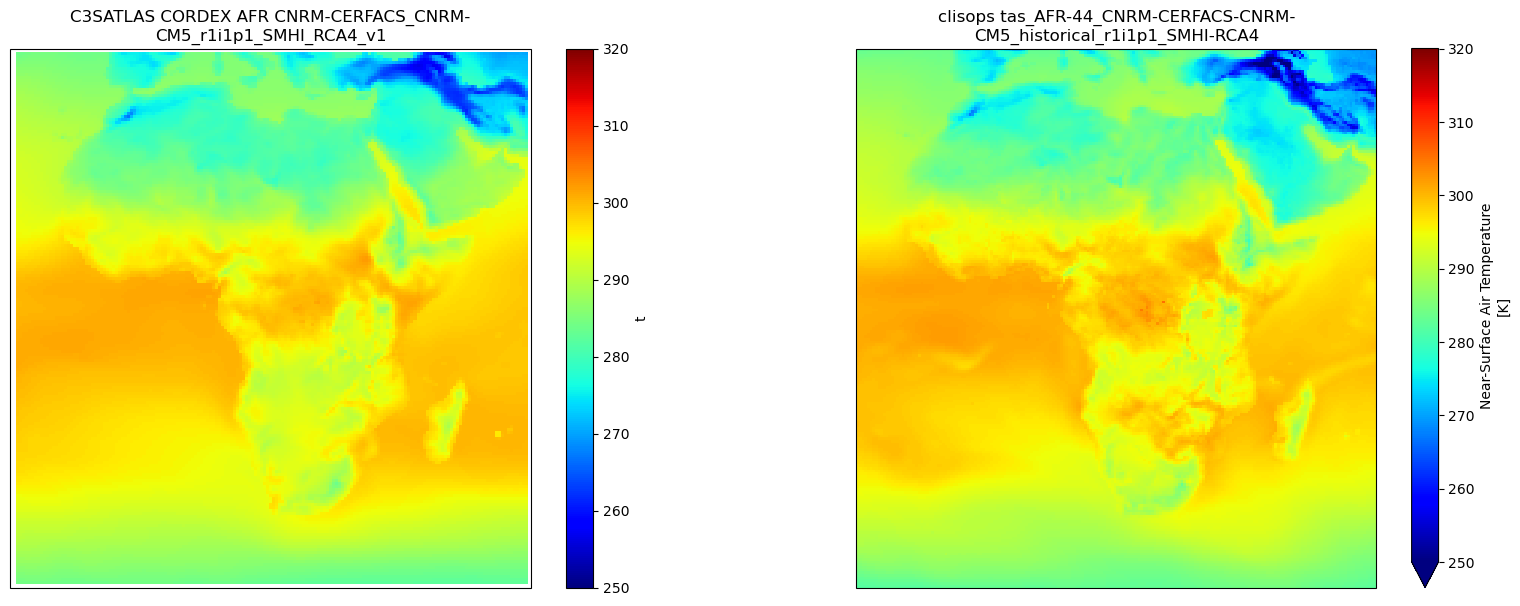

0 clisops tas_AUS-44i_CCCma-CanESM2_historical_r1i1p1_CSIRO-CCAM-2008


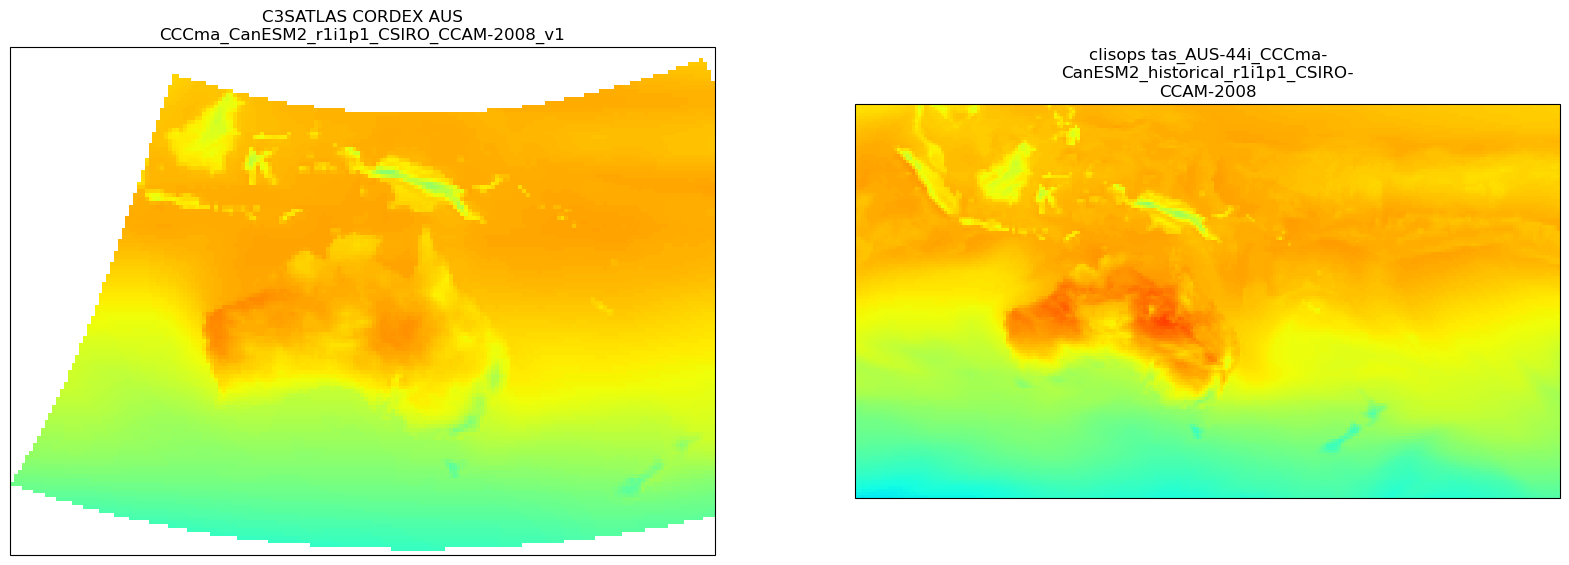

19 clisops tas_NAM-22_NOAA-GFDL-GFDL-ESM2M_historical_r1i1p1_OURANOS-CRCM5


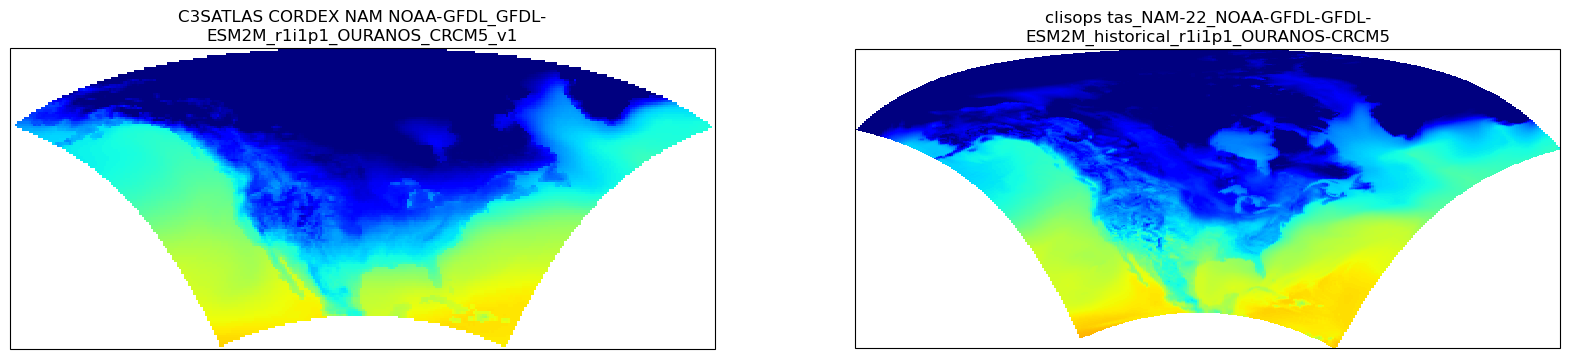

10 clisops tas_SEA-22_NCC-NorESM1-M_historical_r1i1p1_ICTP-RegCM4-7


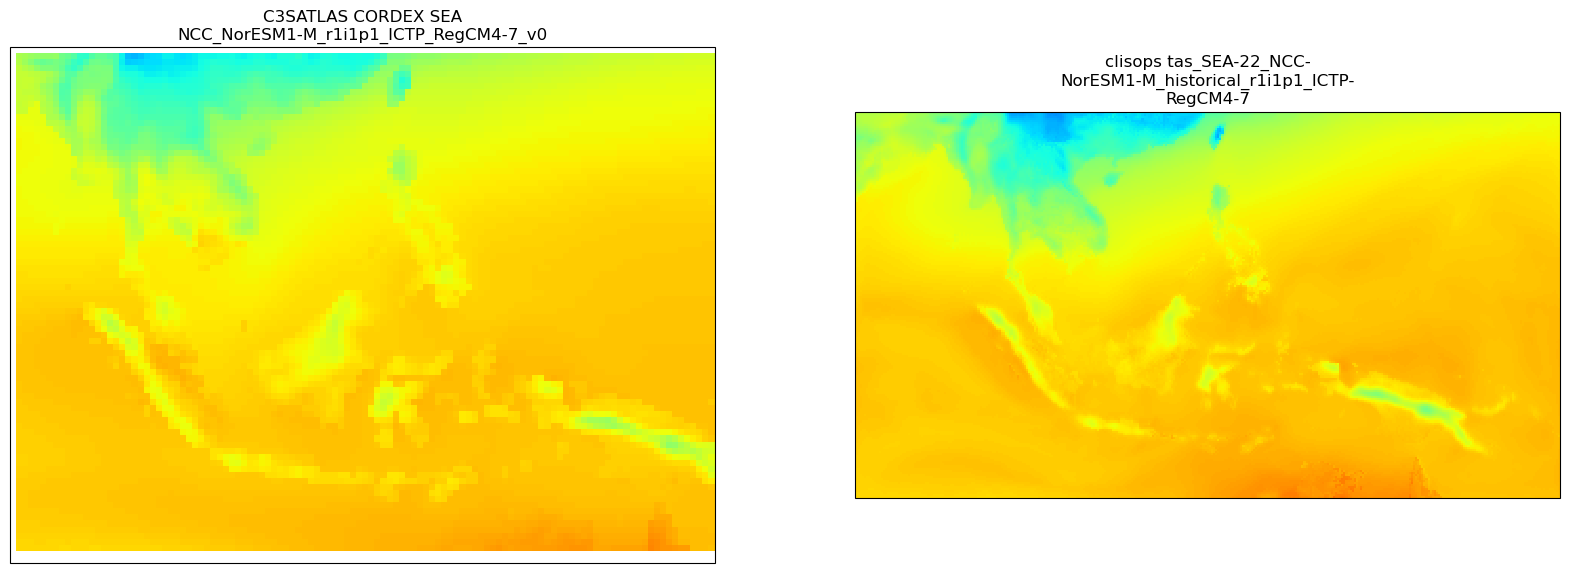

In [5]:
sel_member = {"AFR": 4, "AUS": 0, "NAM": 19, "SEA": 10}
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    # if domain != "AFR": continue
    i = sel_member[domain]
    filepath = glob(f"testdata/ATLAS_v0_CORDEX/{i}_*.nc")[0]
    title1 = "clisops " + "_".join(filepath.split("/")[-1].split("_")[1:7])
    title0 = (
        "C3SATLAS CORDEX "
        + domain
        + " "
        + ds_atlas[domain]["member_id"].values[i]
    )
    
    ds = xr.open_dataset(filepath)

    method = "conservative"
    print(i, title1)    

    ds_regrid = clops.regrid(
        ds,
        method=method,
        adaptive_masking_threshold=1,
        grid="adaptive",
        output_type="xarray",
    )[0]
    plot_ds(
        ds_atlas[domain].t.isel(member=i, time=0) + 273.15,
        ds_regrid.tas.isel(time=0),
        title0,
        title1,
        cbar=domain == "AFR",
    )

## Comparison with ATLAS_v1

In [6]:
import math
import textwrap


def plot_ds(ds_atlas, ds, subtitle0=None, subtitle1=None, cbar=False):
    # Create panel plot
    fig, axes = plt.subplots(
        ncols=2,
        nrows=1,
        figsize=(20, 7),
        subplot_kw={"projection": ccrs.Mercator(central_longitude=150)},
    )

    ds_atlas.plot.pcolormesh(
        ax=axes[0],
        vmin=240,
        vmax=300,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    ds.plot.pcolormesh(
        ax=axes[1],
        vmin=240,
        vmax=300,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    if subtitle0:
        axes[0].title.set_text("\n".join(textwrap.wrap(subtitle0, 40)))
    if subtitle1:
        axes[1].title.set_text("\n".join(textwrap.wrap(subtitle1, 40)))

    for axis in axes.flatten():
        axis.coastlines()
        axis.set_xlabel("lon")
        axis.set_ylabel("lat")
    plt.show()

In [7]:
ds_atlas = {}
for domain in ["EUR-11"]:
    ds_atlas[domain] = xr.open_dataset(
        f"testdata/ATLAS_v1_CORDEX/t_CORDEX-{domain}_historical_mon_197001-200512.nc"
    )

In [8]:
for domain in ["EUR-11"]:
    for i in range(ds_atlas[domain].sizes["member"]):
        print()
        print(i)
        # id example: c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915
        id = f"c3s-cordex.output.{domain}-*.{ds_atlas[domain].rcm_institution.data[i]}.{ds_atlas[domain].gcm_institution.data[i]}-{ds_atlas[domain].gcm_model.data[i]}.historical.{ds_atlas[domain].gcm_variant.data[i]}.{ds_atlas[domain].rcm_institution.data[i]}-{ds_atlas[domain].rcm_model.data[i]}.{ds_atlas[domain].rcm_variant.data[i]}.tas.mon"
        print(id)
        print(id.replace(".", "/") + "/*/*_1970-*.nc")


0
c3s-cordex.output.EUR-11-*.CLMcom.CCCma-CanESM2.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom/CCCma-CanESM2/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

1
c3s-cordex.output.EUR-11-*.GERICS.CCCma-CanESM2.historical.r1i1p1.GERICS-REMO2015.v1.tas.mon
c3s-cordex/output/EUR-11-*/GERICS/CCCma-CanESM2/historical/r1i1p1/GERICS-REMO2015/v1/tas/mon/*/*_1970-*.nc

2
c3s-cordex.output.EUR-11-*.CLMcom-ETH.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-ETH-COSMO-crCLIM-v1-1.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom-ETH/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-ETH-COSMO-crCLIM-v1-1/v1/tas/mon/*/*_1970-*.nc

3
c3s-cordex.output.EUR-11-*.CLMcom.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

4
c3s-cordex.output.EUR-11-*.CNRM.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CNRM-ALADIN63.v2.tas.mon
c3s-cordex/out

60 clisops tas_EUR-11_MPI-M-MPI-ESM-LR_historical_r3i1p1_GERICS-REMO2015


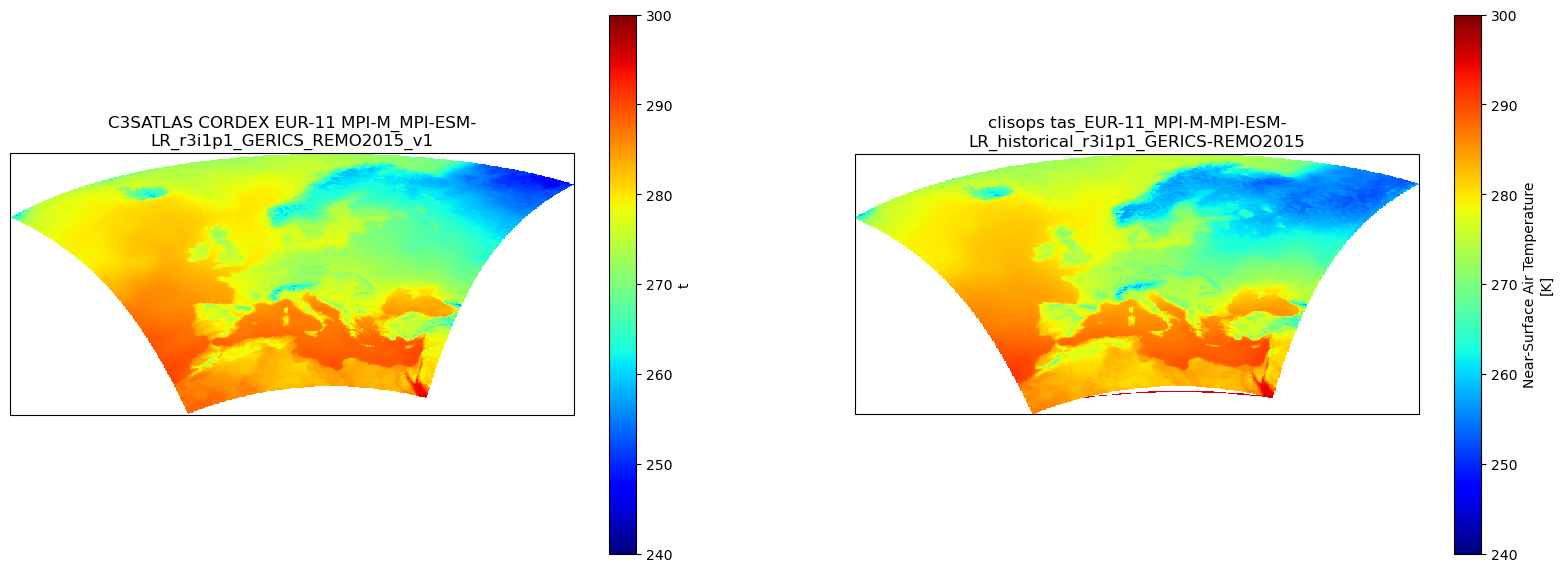

In [9]:
sel_member = {"EUR-11": 60}
for domain in ["EUR-11"]:
    i = sel_member[domain]
    filepath = glob(f"testdata/ATLAS_v1_CORDEX/{i}_*.nc")[0]
    title1 = "clisops " + "_".join(filepath.split("/")[-1].split("_")[1:7])
    title0 = (
        "C3SATLAS CORDEX "
        + domain
        + " "
        + ds_atlas[domain]["member_id"].values[i]
    )
    ds = xr.open_dataset(filepath)

    method = "conservative"
    print(i, title1)

    ds_regrid = clops.regrid(
        ds,
        method=method,
        adaptive_masking_threshold=1,
        grid="adaptive",
        output_type="xarray",
    )[0]
    plot_ds(
        ds_atlas[domain].t.isel(member=i, time=0) + 273.15,
        ds_regrid.tas.isel(time=0),
        title0,
        title1,
        cbar=domain == "EUR-11",
    )

The narrow seam of data points south of the EUR-11 domain for the clisops regridding result comes from the `adaptive masking` (renormalization) that is applied by default. It can be disabled using `adaptive_masking_threshold=0`.

Looking in detail at the generated remapping weights, the "culprit" for this seam of data points outside the EUR-11 domain is a single cell, with seemingly corrupted bounds:

In [10]:
print("Longitude vertices of cell [0, 423]")
for i in range(4):
    print(ds.lon_vertices[0, 423, i].values)
print()
print("Latitude vertices of cell [0, 423]")
for i in range(4):
    print(ds.lat_vertices[0, 423, i].values)

Longitude vertices of cell [0, 423]
36.37637
36.344055
287.24197
0.03760147

Latitude vertices of cell [0, 423]
25.180796
25.074755
25.047943
25.153942


The cell extends quite a bit around the globe at around 25 degrees latitude. In the following the target cells are identified that receive a contribution from that cell (by looking at the calculated conservative weights):

In [11]:
# Read the weights from cache
import sparse as sps
from clisops import CONFIG
from xesmf.smm import read_weights
w = read_weights(CONFIG["clisops:grid_weights"]["local_weights_dir"] + "/weights_ff47f7d25e73cd1376206a5e2cfd2258_2338a6e18b30a0457874c9c2ea261498_unperi_skip-degen_conservative.nc",
                412*424,
                412*424)
w

Format,coo
Data Type,float64
Shape,"(174688, 174688)"
nnz,681378
Density,2.232862407154387e-05
Read-only,True
Size,10.4M
Storage ratio,0.00


In [12]:
W = w.data

# Flattened index of the corrupted source cell
corrupted_source_idx = np.ravel_multi_index((0, 423), (412, 424))

# Find all target entries receiving a contribution by this source cell
mask = W.coords[1] == corrupted_source_idx
target_indices = W.coords[0][mask]
target_weights = W.data[mask]

# Map flat target indices back to 2D (ilat, ilon)
nlat_tgt, nlon_tgt = 412, 424
target_ilat, target_ilon = np.unravel_index(target_indices, (nlat_tgt, nlon_tgt))

# Print all identified cells
for ilat, ilon, w in zip(target_ilat, target_ilon, target_weights):
    print(f"Target cell [{ilat}, {ilon}] ([{ds_regrid.lat[ilat].values}, {ds_regrid.lon[ilon].values}]) receives weight {w} from corrupted source cell")

Target cell [26, 172] ([25.18872, -0.045352]) receives weight 0.0001319069290794396 from corrupted source cell
Target cell [26, 173] ([25.18872, 0.213652]) receives weight 0.005548544751915428 from corrupted source cell
Target cell [26, 174] ([25.18872, 0.472656]) receives weight 0.013701120644124067 from corrupted source cell
Target cell [26, 175] ([25.18872, 0.73166]) receives weight 0.016055952658474565 from corrupted source cell
Target cell [26, 310] ([25.18872, 35.697188]) receives weight 0.00029424763872026307 from corrupted source cell
Target cell [26, 311] ([25.18872, 35.956192]) receives weight 0.14117801655319198 from corrupted source cell
Target cell [26, 312] ([25.18872, 36.215196]) receives weight 0.401042590360892 from corrupted source cell
Target cell [26, 313] ([25.18872, 36.4742]) receives weight 0.09012792948389366 from corrupted source cell
Target cell [27, 175] ([25.311828, 0.73166]) receives weight 0.005790465715252435 from corrupted source cell
Target cell [27, 17

##### The identified target cells are depicted in violet color:

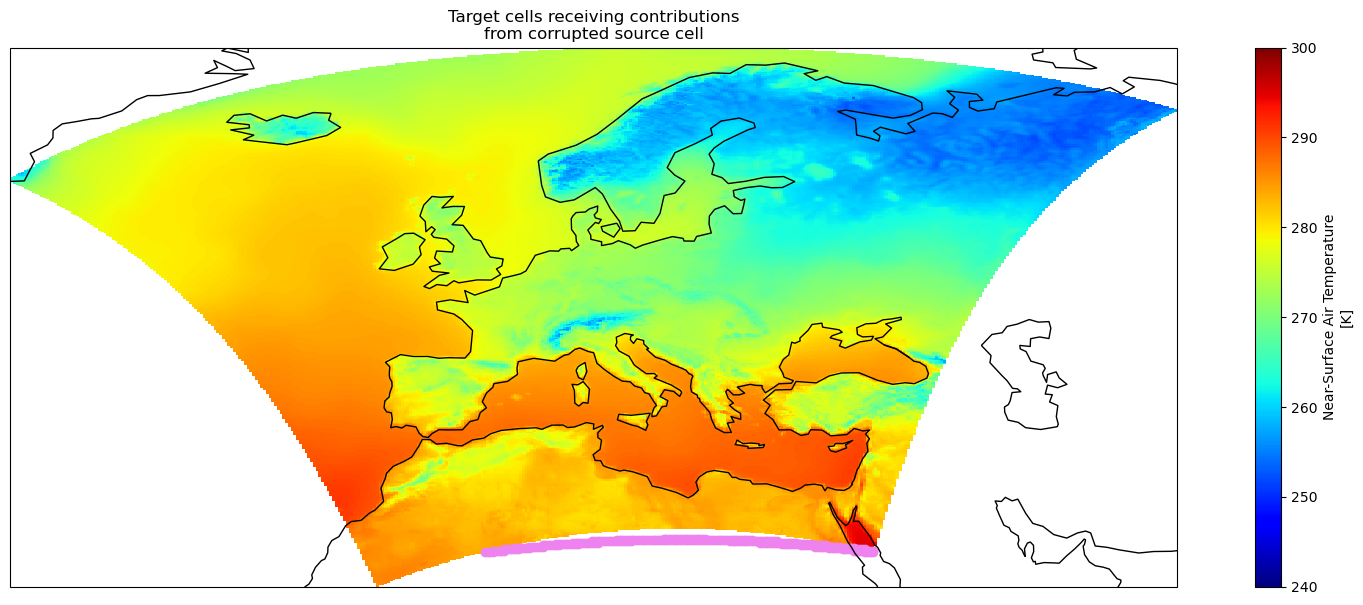

In [13]:
# Create panel plot
fig, ax = plt.subplots(
    figsize=(20, 7),
    subplot_kw={"projection": ccrs.PlateCarree()},
);

_ = ds_regrid.tas.isel(time=0).plot.pcolormesh(
    ax=ax,
    vmin=240,
    vmax=300,
    shading="auto",
    cmap="jet",
);
ax.title.set_text("\n".join(textwrap.wrap("Target cells receiving contributions from corrupted source cell", 40)));

_ = ax.coastlines();
_ = ax.set_xlabel("lon");
_ = ax.set_ylabel("lat");

for t_ilat, t_ilon in zip(target_ilat, target_ilon):
    t_lat = ds_regrid.lat[t_ilat]
    t_lon = ds_regrid.lon[t_ilon]
    _ = ax.scatter(t_lon, t_lat, color='violet', transform=ccrs.PlateCarree());

plt.show()